# Day 09: Parsing and chunking

Today we cover two steps of a RAG pipeline: **parsing** and **chunking**.

```
file → parse → clean → chunk → (Day 10: embed → store)
```

**Bad ingestion means bad RAG.** Embeddings, search and the LLM only see what this step gives them.
If a title is lost or a sentence is cut in half here, no model can fix it later.

| § | Topic |
|---|---|
| 1 | What is parsing |
| 2 | How to parse each type of file, and the best tool for each |
| 3 | Cleaning: common patterns |
| 4 | Chunking (next) |

Samples are in `samples/`: real pages of the Bharatiya Nyaya Sanhita (BNS) 2023, a scan, a table, a Word file, a web page and a video.

In [1]:
import re, subprocess, time, unicodedata
from pathlib import Path
import pandas as pd
import pymupdf

SAMPLES = Path("samples")
CACHE = Path("cache")
CACHE.mkdir(exist_ok=True)

## 1. What is parsing

**Parsing = turning a file into text (and structure) a program can use.**

A file is made for a human to *look at*, not for a program to *read*:

- A **PDF** is a list of drawing instructions: *put this glyph at (x, y), draw this line*. There are no "paragraphs" or "headings" inside it.
- A **scan** is just a picture. There is no text at all until we run OCR.
- A **Word / HTML** file has structure (headings, tables), but also styling, menus and ads we don't want.
- **Audio / video** has no text until a speech-to-text model writes it.

A good parser gives us:
1. **The text**, in the right reading order.
2. **The structure**: headings, sections, tables, lists.
3. **Metadata**: page number, section, timestamp. We need it later to cite the answer ("BNS Section 103, page 34").

Plain text extraction is the simplest parser. Look at what it gives on a real page of the BNS:

In [2]:
doc = pymupdf.open(SAMPLES / "bns_pages.pdf")
page = doc[1]                     # section 101: Murder
text = page.get_text()
print(text[:300])
print("\n... end of the page ...\n")
print(text[text.index("question of fact."):][:200])

Explanation 2.—Where death is caused by bodily injury, the person who causes such
bodily injury shall be deemed to have caused the death, although by resorting to proper
remedies and skilful treatment the death might have been prevented.
Explanation 3.—The causing of the death of a child in the moth

... end of the page ...

question of fact.
Murder.
32
THE GAZETTE OF INDIA EXTRAORDINARY
[Part II—
____________________________________________________________
_____________________________________________________________
___


The text is there, but:
1. The running header (`32 THE GAZETTE OF INDIA…`) and its underlines are mixed into the text.
2. The section title `Murder.` sits in the page margin, so it comes out at the **end** of the page, far from section 101.
3. Lines break where the page ended, not where sentences end.
Parsing is about getting the text **and** getting it right.

## 2. How to parse each type, and the best tool for each

| Document | First choice | Why |
|---|---|---|
| Digital PDF, simple layout | **PyMuPDF** / `pymupdf4llm` | fast, coordinates for your own rules |
| PDF with tables | **pdfplumber** | real rows and cells |
| Complex layout | **Docling** (IBM) | layout model, slower |
| Word, Excel, PowerPoint | **MarkItDown** or Docling | already structured |
| Web page | keep `<main>`, then **MarkItDown** | remove boilerplate first |
| Scan | **Tesseract** / RapidOCR → **Mistral OCR** | OCR only pages without text |
| Audio, video | ffmpeg → **Whisper** | keep timestamps as metadata |

**Lesson:** a heavier tool isn't always better. For one regular layout, a few coordinate rules beat a general layout model.

### 2.1 Digital PDF → PyMuPDF

**Theory:** a digital PDF (made from Word, LaTeX, a website) has a **text layer**: the characters are stored, so we just read them.
PyMuPDF is written in C, so it is very fast, and it also gives the **position** of every block of text.

In [3]:
blocks = page.get_text("blocks")          # (x0, y0, x1, y1, text, ...)
pd.DataFrame([{"x0": round(b[0]), "y0": round(b[1]), "text": b[4][:60]} for b in blocks]).head(8)

,x0,y0,text
0,118,81,Explanation 2.—Where death is caused by bodily...
1,118,123,Explanation 3.—The causing of the death of a c...
2,142,177,"101. Except in the cases hereinafter excepted,..."
3,142,195,(a) if the act by which the death is caused i...
4,142,225,(b) if the act by which the death is caused is...
5,142,266,(c) if the act by which the death is caused i...
6,142,306,(d) if the person committing the act by which...
7,271,359,Illustrations.\n


With positions we can write our own rules: the header is at the top (`y0 < 80`), section titles sit in the margins. Keep only the body:

In [4]:
BODY = pymupdf.Rect(110, 80, 485, page.rect.height)     # x0, y0, x1, y1 in points
print(page.get_text(clip=BODY)[:300])

Explanation 2.—Where death is caused by bodily injury, the person who causes such
bodily injury shall be deemed to have caused the death, although by resorting to proper
remedies and skilful treatment the death might have been prevented.
Explanation 3.—The causing of the death of a child in the moth


**`pymupdf4llm`** turns the PDF into **Markdown** (bold, headings, tables) and can drop headers and footers for you:

In [5]:
import pymupdf4llm

md_text = pymupdf4llm.to_markdown(str(SAMPLES / "bns_pages.pdf"), pages=[1], header=False, footer=False)
print(md_text[:500])

rapidocr_api using backend: rapidocr

=== Document parser messages ===
Using RapidOCR for OCR processing.
_Explanation_ 2. _—_ Where death is caused by bodily injury, the person who causes such bodily injury shall be deemed to have caused the death, although by resorting to proper remedies and skilful treatment the death might have been prevented. 

_Explanation_ 3. _—_ The causing of the death of a child in the mother’s womb is not homicide. But it may amount to culpable homicide to cause the death of a living child, if any part of that child has been brought forth, though the child may not have br


### 2.2 PDF with tables → pdfplumber

**Theory:** plain text loses the grid. A row comes out as `302 Punishment for murder 103` and you can't tell which number belongs to which column.
pdfplumber finds the ruling lines and returns real **rows and cells**.

In [6]:
import pdfplumber

with pdfplumber.open(SAMPLES / "ipc_to_bns.pdf") as pdf:
    rows = pdf.pages[0].extract_tables()[0]

table = pd.DataFrame(rows[1:], columns=rows[0])
print(table.to_markdown(index=False))      # Markdown is what we put in a chunk

| IPC section   | Offence                         | BNS section   |
|:--------------|:--------------------------------|:--------------|
| 302           | Punishment for murder           | 103           |
| 304B          | Dowry death                     | 80            |
| 376           | Punishment for rape             | 64            |
| 379           | Punishment for theft            | 303(2)        |
| 420           | Cheating                        | 318(4)        |
| 498A          | Cruelty by husband or relatives | 85            |


**Tip:** keep a table in **one chunk** (or one chunk per row, with the header repeated). A table cut in half loses its column names.

### 2.3 Complex layout → Docling

**Theory:** multi-column papers, forms and reports need a **layout model** that looks at the page like a person and labels headings, paragraphs, tables and figures.
Docling (IBM, open source) does this locally. It is much slower, and its first run downloads its models.

In [7]:
from docling.document_converter import DocumentConverter

converter = DocumentConverter()
t = time.time()
docling_md = converter.convert(SAMPLES / "bns_pages.pdf", page_range=(2, 2)).document.export_to_markdown()
print(f"{time.time() - t:.1f}s")
print(docling_md[:500])

/Users/sarthakaggarwal/Downloads/Random_stuffs/teach-genai/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1024 10:27:42.587000 18346 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 770/770 [00:00<00:00, 12993.35it/s]


3.4s
Murder.

\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_

\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_

\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_

Explanation 2.-Where death is caused by bodily injury, the person who causes such bodily injury shall be deemed to have caused the de


Slower, and on this page it moved the title `Murder.` away from section 101. A general model doesn't know your document's rules. **Look at the output before you pick a tool.**

### 2.4 Word, Excel, PowerPoint → MarkItDown

**Theory:** Office files already store structure (headings, lists, tables), so we only need to **convert** it to Markdown. No OCR, no layout model.
MarkItDown (Microsoft) is a light converter for many formats.

In [8]:
from markitdown import MarkItDown

markitdown = MarkItDown()
print(markitdown.convert(SAMPLES / "rental_agreement.docx").text_content)

Rental Agreement

This agreement is made on 1 October 2026 at New Delhi between Mr. A. Kumar (Landlord) and Ms. R. Singh (Tenant). All names are made up.

# 1. Property

Flat 4B, Green Park Apartments, New Delhi.

# 2. Rent and deposit

|  |  |
| --- | --- |
| Item | Amount (INR) |
| Monthly rent | 25,000 |
| Security deposit | 50,000 |
| Maintenance | 2,000 |

# 3. Terms

1. Rent is paid by the 5th of every month.
2. Either party can end the agreement with one month's written notice.
3. The deposit is returned within 15 days of the tenant leaving.


### 2.5 Web page → keep `<main>`, then MarkItDown

**Theory:** a web page is mostly **boilerplate**: nav bar, ads, sidebar, footer. It repeats on every page, so every chunk ends up looking the same to search.
Keep only the main content, then convert.

First, the whole page:

In [9]:
print(markitdown.convert(SAMPLES / "section_103.html").text_content)

[Home](/) | [Acts](/acts) | [Login](/login) | [Subscribe](/subscribe)

Get 50% off our legal drafting course! Use code LAW50.

# BNS Section 103: Punishment for murder

Section 103 of the Bharatiya Nyaya Sanhita, 2023 replaced Section 302 of the Indian Penal Code.

## The text

> (1) Whoever commits murder shall be punished with death or imprisonment for life,
> and shall also be liable to fine.

> (2) When a group of five or more persons acting in concert commits murder on the ground of race,
> caste or community, sex, place of birth, language, personal belief or any other similar ground each member
> of such group shall be punished with death or with imprisonment for life, and shall also be liable to fine.

## What changed

* The section number changed from 302 to 103.
* Sub-section (2), murder by a group on grounds such as caste or religion, is new.

### Popular posts

* Top 10 law colleges
* How to file an RTI
© 2026 LawBlog. All rights reserved. | Privacy | Terms | Cookie settings

Nav, ad ("50% off… LAW50"), popular posts and the cookie footer are all in there. Now only `<main>`:

In [10]:
import io
from bs4 import BeautifulSoup
from markitdown import StreamInfo

def html_to_markdown(path):
    soup = BeautifulSoup(path.read_text(), "html.parser")
    main = soup.find("main") or soup.find("article") or soup.body
    return markitdown.convert_stream(io.BytesIO(str(main).encode()), stream_info=StreamInfo(extension=".html")).text_content

print(html_to_markdown(SAMPLES / "section_103.html"))

# BNS Section 103: Punishment for murder

Section 103 of the Bharatiya Nyaya Sanhita, 2023 replaced Section 302 of the Indian Penal Code.

## The text

> (1) Whoever commits murder shall be punished with death or imprisonment for life,
> and shall also be liable to fine.

> (2) When a group of five or more persons acting in concert commits murder on the ground of race,
> caste or community, sex, place of birth, language, personal belief or any other similar ground each member
> of such group shall be punished with death or with imprisonment for life, and shall also be liable to fine.

## What changed

* The section number changed from 302 to 103.
* Sub-section (2), murder by a group on grounds such as caste or religion, is new.


### 2.6 Scan → OCR (Tesseract)

**Theory:** a scanned page is **one image**, with no text layer. OCR (optical character recognition) reads the letters from the pixels.
First check whether a page needs OCR at all: 0 characters and 1 image means it is a scan.

In [11]:
for name in ["bns_pages.pdf", "bns_scanned.pdf"]:
    with pymupdf.open(SAMPLES / name) as d:
        p = d[0]
        print(f"{name:16} chars: {len(p.get_text()):5}  images: {len(p.get_images())}")

bns_pages.pdf    chars:  1463  images: 7
bns_scanned.pdf  chars:     0  images: 1


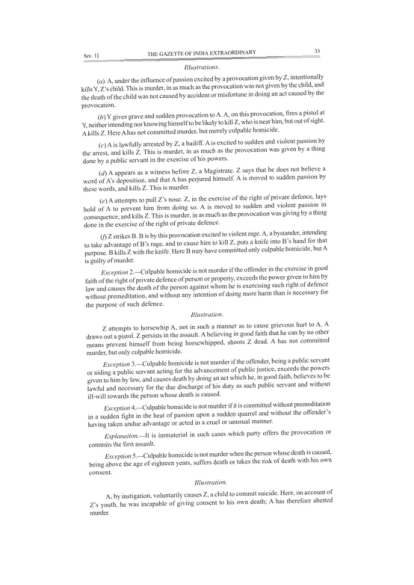

In [12]:
from IPython.display import Image, display

scan = pymupdf.open(SAMPLES / "bns_scanned.pdf")[0]
display(Image(scan.get_pixmap(dpi=50).tobytes("png")))

In [13]:
import pytesseract
from PIL import Image as PILImage

image = PILImage.open(io.BytesIO(scan.get_pixmap(dpi=200).tobytes("png")))
ocr_text = pytesseract.image_to_string(image)
print(ocr_text[:500])

See. 1] THE GAZETTE OF INDIA EXTRAORDINARY 3

Illustrations.

(a) A, under the influence of passion excited by a provocation given by Z, intentionally
kills Y, Z’s child. This is murder, in as much as the provocation was not given by the child, and
the death of the child was not caused by accident or misfortune in doing an act caused by the
provocation.

(b) Y gives grave and sudden provocation to A. A, on this provocation, fires a pistol at
Y, neither intending nor knowing himself to be fikely 


Good, but not perfect: small mistakes like `Ais` for `A is`. For law, one wrong letter or section number changes the meaning.

**Rules:** OCR only pages with no text layer · always keep the page number · for handwriting, stamps, bad photos and complex tables, use a paid OCR (Mistral OCR) or a vision LLM (Day 07).

### 2.7 Audio, video → ffmpeg → Whisper

**Theory:** first pull the audio out of the video with **ffmpeg**, then a speech-to-text model (**Whisper**) writes the text with **timestamps**.
The timestamps become metadata, so an answer can say "at 0:07".

In [ ]:
audio_path = CACHE / "from_video.wav"
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(SAMPLES / "section_103.mp4"),"-vn", "-ac", "1", "-ar", "16000", str(audio_path)], check=True)
print(audio_path, audio_path.stat().st_size // 1024, "KB")

cache/from_video.wav 970 KB


`-vn` drops the video, `-ac 1` makes it mono, `-ar 16000` resamples to 16 kHz, which is what Whisper expects.

In [15]:
from faster_whisper import WhisperModel

whisper = WhisperModel("base.en", device="cpu", compute_type="int8")
segments, _ = whisper.transcribe(str(audio_path))
pd.DataFrame([{"start": round(s.start, 1), "end": round(s.end, 1), "text": s.text.strip()} for s in segments])

objc[18346]: Class AVFFrameReceiver is implemented in both /Users/sarthakaggarwal/Downloads/Random_stuffs/teach-genai/.venv/lib/python3.14/site-packages/cv2/.dylibs/libavdevice.61.3.100.dylib (0x1133683a8) and /Users/sarthakaggarwal/Downloads/Random_stuffs/teach-genai/.venv/lib/python3.14/site-packages/av/.dylibs/libavdevice.62.1.100.dylib (0x14a8ac3a8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[18346]: Class AVFAudioReceiver is implemented in both /Users/sarthakaggarwal/Downloads/Random_stuffs/teach-genai/.venv/lib/python3.14/site-packages/cv2/.dylibs/libavdevice.61.3.100.dylib (0x1133683f8) and /Users/sarthakaggarwal/Downloads/Random_stuffs/teach-genai/.venv/lib/python3.14/site-packages/av/.dylibs/libavdevice.62.1.100.dylib (0x14a8ac3f8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.


,start,end,text
0,0.0,4.3,"Welcome to khanum.ai today, one section of the..."
1,4.3,7.4,Section 103 is the punishment for murder.
2,7.4,12.7,Whoever commits murder shall be punished with ...
3,12.7,19.4,The second part covers a group of five or more...
4,19.4,24.5,face of birth language or personal belief. Eac...
5,24.5,28.1,This was Section 302 or the Old Indian Penal C...
6,28.1,31.0,"Remember, this is information not legal advice."


On a Mac you may see an `objc ... is implemented in both` warning: Docling's OpenCV and Whisper's PyAV each bring a copy of the same video library. It doesn't affect the result.

Mostly right, but domain words come out wrong: the script said "Kanoon dot AI" and "place of birth", Whisper wrote `khanum.ai` and `face of birth`. Passing the vocabulary as `initial_prompt` helps. Always read the transcript.

## 3. Cleaning: common patterns

Parsers leave small problems in the text. They look harmless, but they break search: to a computer `offender’s` and `offender's` are **different words**.

| Problem | Example | Fix |
|---|---|---|
| Unicode variants | `Oﬀence`, non-breaking space | NFKC normalisation |
| Curly quotes and dashes | `offender’s`, `—` | map to plain ASCII |
| Invisible characters | zero-width space, soft hyphen | delete them |
| Hyphenation | `pun-\nishment` | join across lines |
| Broken lines | a sentence split over lines | join single line breaks |
| Running headers, page numbers | `32 THE GAZETTE OF INDIA…` | regex, or drop lines that repeat on every page |
| Extra whitespace | `An  Act   to`, many blank lines | collapse |

One small demo for each, then one `clean()` function.

### 3.1 Unicode normalisation (NFKC)

**Theory:** the same letters can be stored as different characters. Typeset PDFs use **ligatures** (`ﬀ` is one character for "ff"), and many files use a non-breaking space instead of a space.
Unicode **NFKC** rewrites them to their plain form.

In [16]:
messy = "Oﬀence\u00a0under\u00a0Section ①⓪③"
fixed = unicodedata.normalize("NFKC", messy)
print(repr(messy))
print(repr(fixed))
print("Offence" in messy, "Offence" in fixed)

'Oﬀence\xa0under\xa0Section ①⓪③'
'Offence under Section 103'
False True


### 3.2 Curly quotes and dashes

**Theory:** Word and PDFs use curly quotes (`’ “ ”`) and long dashes (`– —`). OCR and users usually type straight ones. Map them all to one form.

In [17]:
QUOTES = str.maketrans({"’": "'", "‘": "'", "“": '"', "”": '"', "–": "-", "—": "-"})

text_layer, from_ocr = "offender’s", "offender's"
print(text_layer == from_ocr, "->", text_layer.translate(QUOTES) == from_ocr.translate(QUOTES))

False -> True


### 3.3 Invisible characters

**Theory:** some characters print as nothing: zero-width space (`\u200b`), soft hyphen (`\u00ad`), byte-order mark (`\ufeff`), control characters. They split words silently.

In [18]:
INVISIBLE_RE = re.compile(r"[\u200b\u200c\u200d\u00ad\ufeff\x00-\x08\x0b\x0c\x0e-\x1f]")

messy = "pun\u00adish\u200bment"
print(messy, "| looks fine, but equal to 'punishment'?", messy == "punishment")
print(INVISIBLE_RE.sub("", messy) == "punishment")

pun­ish​ment | looks fine, but equal to 'punishment'? False
True


### 3.4 Hyphenation across lines

**Theory:** when a word doesn't fit at the end of a line, the PDF breaks it with a hyphen. Search for "punishment" won't find `pun-\nishment`.

In [19]:
messy = "shall be liable to pun-\nishment for life"
print(re.sub(r"(\w)-\n(\w)", r"\1\2", messy))

shall be liable to punishment for life


### 3.5 Broken lines

**Theory:** a PDF breaks lines where the page width ends, not where sentences end. Join a single line break into a space, but keep blank lines (paragraph breaks).
Careful: in legal text a new line can start a new clause like `(a)`, so look at your text first.

In [20]:
messy = "Whoever commits murder shall be\npunished with death or\nimprisonment for life.\n\n(2) When a group..."
print(re.sub(r"(?<!\n)\n(?!\n|\()", " ", messy))

Whoever commits murder shall be punished with death or imprisonment for life.

(2) When a group...


### 3.6 Running headers and page numbers

**Theory:** every page repeats a header or footer (`32 THE GAZETTE OF INDIA EXTRAORDINARY`, `Page 3 of 10`). In chunks, they are noise that makes every chunk look alike.

Two ways: a **regex** when you know the pattern, or find **lines that repeat on most pages** when you don't.

In [21]:
HEADER_RE = re.compile(r"^\d*\s*THE GAZETTE OF INDIA EXTRAORDINARY.*$|^\[Part II.*$|^Sec\. 1\].*$|^_+$|^Page \d+( of \d+)?$", re.M)

raw = page.get_text()
print("removed:", [m.group() for m in HEADER_RE.finditer(raw)][:4])

removed: ['32\nTHE GAZETTE OF INDIA EXTRAORDINARY', '[Part II—', '____________________________________________________________', '_____________________________________________________________']


In [22]:
from collections import Counter

def repeated_lines(pages, share=0.6):
    """Lines that appear on at least `share` of the pages, ignoring digits (page numbers)."""
    seen = Counter()
    for text in pages:
        seen.update({re.sub(r"\d+", "#", line.strip()) for line in text.splitlines() if line.strip()})
    return [line for line, n in seen.items() if n >= share * len(pages)]

pages = [p.get_text() for p in doc][1:]          # pages 2-5
repeated_lines(pages)

['#',
 '_____________________________________________________________',
 'THE GAZETTE OF INDIA EXTRAORDINARY',
 'Illustrations.',
 '____________________________________________________________',
 '________________________________________________________',
 'murder.',
 '___________________________________________________________']

It found the header, the page numbers (`#`) and the underlines without us writing a pattern. But it also found `Illustrations.` and `murder.`, which are **real content** that happens to repeat.
So use it to *find* candidates, then review the list before deleting anything.

### 3.7 Extra whitespace

**Theory:** parsers leave double spaces, tabs and long runs of blank lines. Collapse them so chunk sizes and tokens are honest.

In [23]:
messy = "An  Act \t to   consolidate\n\n\n\n\nthe provisions"
messy = re.sub(r"[ \t]+", " ", messy)
messy = re.sub(r"\n{3,}", "\n\n", messy)
print(repr(messy))

'An Act to consolidate\n\nthe provisions'


### 3.8 All together

The order matters: normalise characters first, then fix lines, then whitespace.

In [24]:
def clean(text):
    text = unicodedata.normalize("NFKC", text)        # ligatures, odd spaces
    text = text.translate(QUOTES)                     # curly quotes and dashes
    text = INVISIBLE_RE.sub("", text)                 # zero-width, soft hyphen
    text = HEADER_RE.sub("", text)                    # running headers
    text = re.sub(r"(\w)-\n(\w)", r"\1\2", text)    # hyphenation
    text = re.sub(r"[ \t]+", " ", text)               # repeated spaces
    text = re.sub(r"\n{3,}", "\n\n", text)           # blank-line runs
    return text.strip()

raw = page.get_text()
cleaned = clean(raw)
print(f"{len(raw)} chars -> {len(cleaned)} chars\n")
print(cleaned[cleaned.index("question of fact."):][:200])

3869 chars -> 3453 chars

question of fact.
Murder.


**Rule:** write cleaning rules **after** looking at your parser's output. Every document set has its own mess. Keep the rules small and test each one, like we did above.

Next: **chunking**.